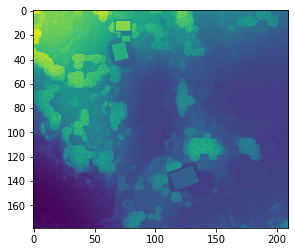

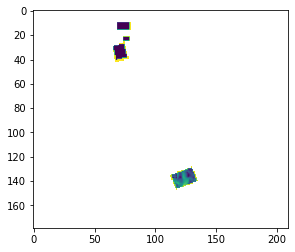

In [1]:
import rasterio as rio
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

elevation = rio.open('data/solar_rooftop.tif').read(1)
plt.imshow(elevation)

buildings = gpd.read_file('data/solar_rooftop.geojson')
buildings.plot()

elevation = rio.open('data/slope_cropped.tif').read(1)
plt.imshow(elevation)

In [2]:
from pvlib import location, irradiance, atmosphere
import pvlib
import pandas as pd
import numpy as np
from tzwhere import tzwhere
import geopandas as gpd

tzwhere = tzwhere.tzwhere()

# variables needed 
buildings = gpd.read_file('data/solar_rooftop.geojson') # footprint geometry
elevation = 20 # in meters
tilt = 0  # horizontal
azimuth = 180  # south facing

polygon = buildings.geometry.iloc[0]
latitude, longitude = polygon.centroid.y, polygon.centroid.x
timezone_str = tzwhere.tzNameAt(latitude, longitude)

site_location = location.Location(latitude, longitude, altitude=elevation, tz=timezone_str)
times = pd.date_range('2024-01-01 00:00:00', '2024-12-31 23:59:59', freq='1h', tz= site_location.tz)
solar_position = site_location.get_solarposition(times)

dni_extra = irradiance.get_extra_radiation(times)

# Calculate air mass
airmass = atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
pressure = atmosphere.alt2pres(elevation)
airmass_absolute = atmosphere.get_absolute_airmass(airmass, pressure)

# Get clear-sky model
clearsky = site_location.get_clearsky(times)

# Calculate total irradiance on the tilted surface
total_irradiance = irradiance.get_total_irradiance(
    surface_tilt=tilt,
    surface_azimuth=azimuth,
    dni=clearsky['dni'],
    ghi=clearsky['ghi'],
    dhi=clearsky['dhi'],
    solar_zenith=solar_position['apparent_zenith'],
    solar_azimuth=solar_position['azimuth'],
    dni_extra=dni_extra,
    airmass=airmass_absolute    
)

# Get annual sum of total solar irradiation
annual_irradiation = total_irradiance['poa_global'].sum() * 1e-3  # kWh/m²

print(f'Annual Solar Irradiation: {annual_irradiation:.2f} kWh/m²')

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


Annual Solar Irradiation: 2464.39 kWh/m²


### Next steps

1. Integrate elevation data from raster
2. Add cloud cover proportion to DNI
3. Add surface tilt and azimuth from raster
4. Add shading effect

In [3]:
def solar_irradiation_from_elevation(lat, lon, elevation, row, col, year=2023): # row, col will be used to get slope and aspect later
    tilt = 0  # horizontal
    azimuth = 180  # south facing

    latitude, longitude = lat, lon
    timezone_str = tzwhere.tzNameAt(latitude, longitude)

    site_location = location.Location(latitude, longitude, altitude=elevation, tz=timezone_str)
    times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz= site_location.tz)
    solar_position = site_location.get_solarposition(times)

    dni_extra = irradiance.get_extra_radiation(times)

    # Calculate air mass
    airmass = atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
    pressure = atmosphere.alt2pres(elevation)
    airmass_absolute = atmosphere.get_absolute_airmass(airmass, pressure)

    # Get clear-sky model
    clearsky = site_location.get_clearsky(times)

    # Calculate total irradiance on the tilted surface
    total_irradiance = irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=clearsky['dni'],
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'],
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )

    # Get annual sum of total solar irradiation
    annual_irradiation = total_irradiance['poa_global'].sum() * 1e-3  # kWh/m²
    if annual_irradiation > 0: 
        print(f'Annual Solar Irradiation: {annual_irradiation:.2f} kWh/m²')
        
    return annual_irradiation

In [20]:
import rasterio
from rasterio.mask import mask
import geopandas as gpd
import numpy as np


def main(raster_path, geojson_path, output_path):
    # Read the GeoJSON file
    gdf = gpd.read_file(geojson_path)

    with rasterio.open(raster_path) as src:
        # Clip the raster with the GeoJSON
        out_image, out_transform = mask(src, gdf.geometry, crop=True)
        out_image[out_image < 0] = np.nan
        out_meta = src.meta.copy()
        
        # Update the metadata to reflect the new shape and transform
        out_meta.update({"driver": "GTiff",
                         "height": out_image.shape[1],
                         "width": out_image.shape[2],
                         "transform": out_transform})
        
        # Iterate over the non-NaN elements
        new_data = np.full(out_image.shape, np.nan, dtype=out_image.dtype)
        for row in range(out_image.shape[1]):
            for col in range(out_image.shape[2]):
                pixel_value = out_image[0, row, col]
                if not np.isnan(pixel_value):
                    # Convert row, col to lat, lon
                    lon, lat = rasterio.transform.xy(out_transform, row, col, offset='center')
                    # Apply the function
                    new_pixel_value = solar_irradiation_from_elevation(lat, lon, pixel_value, row, col)
                    new_data[0, row, col] = new_pixel_value

        # Write the new raster data to a new file
        with rasterio.open(output_path, 'w', **out_meta) as dest:
            dest.write(new_data)

    return new_data

# Example usage
raster_path = 'data/solar_rooftop.tif'
geojson_path = 'data/solar_rooftop.geojson'
output_path = 'data/solar_rooftop_output.tif'
output_raster = main(raster_path, geojson_path, output_path)

Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2458.90 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irradiation: 2459.05 kWh/m²
Annual Solar Irr

### Slope and Aspect

In [2]:
import rasterio
import json
import pvlib
from tzwhere import tzwhere
from rasterio.features import geometry_mask
from rasterio.mask import mask
from rasterio.enums import Resampling
from shapely.geometry import shape
from scipy.ndimage import sobel
from pvlib import location, irradiance, atmosphere
import pandas as pd
import numpy as np
import geopandas as gpd
import openmeteo_requests

    
def main(raster_path, geojson_path, output_path, year=2023, model='both'):

    with rasterio.open(raster_path) as src:
        # Clip the raster with the GeoJSON
        elevation = src.read(1)
        profile = src.profile
        transform = src.transform

        tzwheres = tzwhere.tzwhere()

        longitude, latitude = rasterio.transform.xy(transform, src.height // 2, src.width // 2)

        timezone_str = tzwheres.tzNameAt(latitude, longitude)
        cloud_cover = get_cloud_cover(latitude, longitude, timezone_str, year)
        cloud_cover = cloud_cover/100
                                         
        elevation, slope, aspect = calculate_slope_aspect(elevation)
        elevation_cropped, slope_cropped, aspect_cropped = crop_to_geojson(elevation, slope, aspect, profile, geojson_path)
        
        # Iterate over the non-NaN elements
        new_data_cloud = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        new_data_clear = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        a = 0

        for row in range(elevation_cropped.shape[0]):
            for col in range(elevation_cropped.shape[1]):
                
                elevation_value = elevation_cropped[row, col]
                slope_value = slope_cropped[row, col]
                aspect_value = aspect_cropped[row, col]

                if not np.isnan(elevation_value):
                    a += 1
                    
                    # Convert row, col to lat, lon
                    lon, lat = rasterio.transform.xy(transform, row, col, offset='center')

                    # Apply the function
                    annual_irradiation_pixel_cloud, annual_irradiation_pixel_clear = solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation_value, 
                                                                                slope_value, aspect_value, year, model)
                    new_data_cloud[row, col] = annual_irradiation_pixel_cloud
                    new_data_clear[row, col] = annual_irradiation_pixel_clear
        
        print(a, 'pixels covered.')

        if model == 'cloud' or model == 'both':
            with rasterio.open(f"{output_path}_cloud.tif", 'w', **profile) as dest:
                dest.write(new_data_cloud, 1)

        if model == 'clear' or model == 'both':
            with rasterio.open(f"{output_path}_clear.tif", 'w', **profile) as dest:
                dest.write(new_data_clear, 1)

    return new_data_cloud, new_data_clear

def get_cloud_cover(lat, lon, timezone, year=2023):
	openmeteo = openmeteo_requests.Client()

	url = "https://archive-api.open-meteo.com/v1/archive"
	
	params = {
		"latitude": lat,
		"longitude": lon,
		"hourly": "cloud_cover",
		"timezone": timezone,
		"start_date": f"{year}-01-01",
		"end_date": f"{year}-12-31"
	}
	responses = openmeteo.weather_api(url, params=params)

	# Process first location. Add a for-loop for multiple locations or weather models
	response = responses[0]
	print(f"Coordinates {response.Latitude()}°N {response.Longitude()}°E")
	print(f"Elevation {response.Elevation()} m asl")
	print(f"Timezone {response.Timezone()} {response.TimezoneAbbreviation()}")
	print(f"Timezone difference to GMT+0 {response.UtcOffsetSeconds()} s")

	# Process hourly data. The order of variables needs to be the same as requested.
	hourly = response.Hourly()
	hourly_cloud_cover = hourly.Variables(0).ValuesAsNumpy()

	return hourly_cloud_cover

def calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover):
    """
    Calculate the total irradiance on a tilted surface under cloudy conditions.
    
    Parameters:
    tilt (float): Surface tilt angle in degrees
    azimuth (float): Surface azimuth angle in degrees
    clearsky (pd.DataFrame): DataFrame containing 'dni', 'ghi', 'dhi' for clear sky conditions
    solar_position (pd.DataFrame): DataFrame containing 'apparent_zenith' and 'azimuth'
    dni_extra (pd.Series): Extraterrestrial DNI
    airmass_absolute (pd.Series): Absolute airmass
    cloud_cover (pd.Series): Cloud cover fraction (0 to 1)
    
    Returns:
    pd.DataFrame: DataFrame with columns 'poa_global', 'poa_direct', 'poa_diffuse', 'poa_ground'
    """
    # Adjust DNI and DHI for cloud cover
    dni_cloudy = clearsky['dni'] * (1 - cloud_cover)
    dhi_cloudy = clearsky['dhi'] * (1 + cloud_cover)
    
    # Calculate the total irradiance on a tilted surface under cloudy conditions
    total_irradiance = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=dni_cloudy,
        ghi=clearsky['ghi'],  # GHI is not directly used in the calculation but can be provided
        dhi=dhi_cloudy,
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )
    
    return total_irradiance
    

def solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation=10, slope=0, aspect=180, year=2023, model='cloud'):
    tilt = slope
    azimuth = aspect

    latitude, longitude = lat, lon
    

    site_location = location.Location(latitude, longitude, altitude=elevation, tz=timezone_str)
    times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz= site_location.tz)
    solar_position = site_location.get_solarposition(times)


    dni_extra = irradiance.get_extra_radiation(times)

    # Calculate air mass
    airmass = atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
    pressure = atmosphere.alt2pres(elevation)
    airmass_absolute = atmosphere.get_absolute_airmass(airmass, pressure)   

    # Get clear-sky model
    clearsky = site_location.get_clearsky(times)

    # Calculate total irradiance on the tilted surface (cloudy and clear sky)
    total_irradiance_cloudy = calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, 
                                                                dni_extra, airmass_absolute, cloud_cover)

    total_irradiance_clear = irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=clearsky['dni'],
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'],
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )

    # Get annual sum of total solar irradiation
    annual_irradiation_clear = total_irradiance_clear['poa_global'].sum() * 1e-3  # kWh/m²
    annual_irradiation_cloudy = total_irradiance_cloudy['poa_global'].sum() * 1e-3  # kWh/m²
    
    if model == 'cloud':
        return annual_irradiation_cloudy
    if model == 'clear':
        return annual_irradiation_clear
    if model == 'both':
        return annual_irradiation_cloudy, annual_irradiation_clear


def calculate_slope_aspect(elevation):

    # Calculate the gradient in the x and y directions
    dx = sobel(elevation, axis=1)  # Sobel filter to calculate gradient along x-axis
    dy = sobel(elevation, axis=0)  # Sobel filter to calculate gradient along y-axis
    slope = np.arctan(np.sqrt(dx**2 + dy**2))

    slope_degrees = np.degrees(slope)
    
    # Calculate aspect
    aspect = np.arctan2(-dx, dy)
    aspect_degrees = np.degrees(aspect)
    aspect_degrees = np.where(aspect_degrees < 0, 90.0 - aspect_degrees, 360.0 - aspect_degrees + 90.0)
    aspect_degrees = np.where(aspect_degrees > 360.0, aspect_degrees - 360.0, aspect_degrees)

    return elevation, slope_degrees, aspect_degrees

def crop_to_geojson(elevation, slope, aspect, profile, geojson_path):
    with open(geojson_path) as f:
        geojson = json.load(f)

    geoms = [shape(feature['geometry']) for feature in geojson['features']]
    masks = [geometry_mask([geom], transform=profile['transform'], invert=True, out_shape=(profile['height'], profile['width'])) for geom in geoms]

    slope_cropped = np.full_like(slope, np.nan)
    aspect_cropped = np.full_like(aspect, np.nan)
    elevation_cropped = np.full_like(elevation, np.nan)

    for mask in masks:
        slope_cropped[mask] = slope[mask]
        aspect_cropped[mask] = aspect[mask]
        elevation_cropped[mask] = elevation[mask]

        out_slope_path = 'data/slope_cropped.tif'
        out_aspect_path = 'data/aspect_cropped.tif'

        with rasterio.open(out_slope_path, 'w', **profile) as dst:
            dst.write(slope_cropped, 1)

        with rasterio.open(out_aspect_path, 'w', **profile) as dst:
            dst.write(aspect_cropped, 1)


    return elevation_cropped, slope_cropped, aspect_cropped


# Paths to input DSM raster and GeoJSON file
dsm_path = 'data/philippines/solar_rooftop.tif'
geojson_path = 'data/philippines/solar_rooftop.geojson'
output_path = 'data/preds/manila'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

Coordinates 14.727592468261719°N 120.30697631835938°E
Elevation 32.0 m asl
Timezone b'Asia/Manila' b'PST'
Timezone difference to GMT+0 28800 s
612 pixels covered.


In [4]:
import rasterio
import json
import pvlib
from tzwhere import tzwhere
from rasterio.features import geometry_mask
from scipy.ndimage import sobel
from shapely.geometry import shape
import pandas as pd
import numpy as np
import openmeteo_requests

def main(raster_path, geojson_path, output_path, year=2023, model='both'):
    with rasterio.open(raster_path) as src:
        # Clip the raster with the GeoJSON
        elevation = src.read(1)
        profile = src.profile
        transform = src.transform

        # Get the timezone
        tzwheres = tzwhere.tzwhere()
        longitude, latitude = rasterio.transform.xy(transform, src.height // 2, src.width // 2)
        timezone_str = tzwheres.tzNameAt(latitude, longitude)

        # Get cloud cover data
        cloud_cover = get_cloud_cover(latitude, longitude, timezone_str, year) / 100

        # Calculate slope and aspect
        elevation, slope, aspect = calculate_slope_aspect(elevation)

        # Crop to GeoJSON
        elevation_cropped, slope_cropped, aspect_cropped = crop_to_geojson(elevation, slope, aspect, profile, geojson_path)

        # Prepare output arrays
        new_data_cloud = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        new_data_clear = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        total_pixels = np.count_nonzero(~np.isnan(elevation_cropped))

        # Process each pixel
        for row in range(elevation_cropped.shape[0]):
            for col in range(elevation_cropped.shape[1]):
                if not np.isnan(elevation_cropped[row, col]):
                    lon, lat = rasterio.transform.xy(transform, row, col, offset='center')
                    annual_irradiation_cloud, annual_irradiation_clear = solar_irradiation_from_elevation(
                        lat, lon, cloud_cover, timezone_str, elevation_cropped[row, col], slope_cropped[row, col], 
                        aspect_cropped[row, col], year, model
                    )
                    new_data_cloud[row, col] = annual_irradiation_cloud
                    new_data_clear[row, col] = annual_irradiation_clear

        print(f'{total_pixels} pixels covered.')

        # Save the results
        save_raster(output_path, new_data_cloud, profile, suffix='cloud', model=model)
        save_raster(output_path, new_data_clear, profile, suffix='clear', model=model)

    return new_data_cloud, new_data_clear

def get_cloud_cover(lat, lon, timezone, year=2023):
    openmeteo = openmeteo_requests.Client()
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "cloud_cover",
        "timezone": timezone,
        "start_date": f"{year}-01-01",
        "end_date": f"{year}-12-31"
    }
    responses = openmeteo.weather_api(url, params=params)
    hourly_cloud_cover = responses[0].Hourly().Variables(0).ValuesAsNumpy()
    return hourly_cloud_cover

def calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover):
    dni_cloudy = clearsky['dni'] * (1 - cloud_cover)
    dhi_cloudy = clearsky['dhi'] * (1 + cloud_cover)
    total_irradiance = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=dni_cloudy,
        ghi=clearsky['ghi'],
        dhi=dhi_cloudy,
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )
    return total_irradiance

def solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation=10, slope=0, aspect=180, year=2023, model='cloud'):
    site_location = pvlib.location.Location(lat, lon, altitude=elevation, tz=timezone_str)
    times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz=site_location.tz)
    solar_position = site_location.get_solarposition(times)
    dni_extra = pvlib.irradiance.get_extra_radiation(times)
    airmass = pvlib.atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
    pressure = pvlib.atmosphere.alt2pres(elevation)
    airmass_absolute = pvlib.atmosphere.get_absolute_airmass(airmass, pressure)
    clearsky = site_location.get_clearsky(times)
    total_irradiance_cloudy = calculate_cloudy_total_irradiance(
        slope, aspect, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover
    )
    total_irradiance_clear = pvlib.irradiance.get_total_irradiance(
        surface_tilt=slope,
        surface_azimuth=aspect,
        dni=clearsky['dni'],
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'],
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )
    annual_irradiation_clear = total_irradiance_clear['poa_global'].sum() * 1e-3  # kWh/m²
    annual_irradiation_cloudy = total_irradiance_cloudy['poa_global'].sum() * 1e-3  # kWh/m²

    if model == 'cloud':
        return annual_irradiation_cloudy
    if model == 'clear':
        return annual_irradiation_clear
    if model == 'both':
        return annual_irradiation_cloudy, annual_irradiation_clear

def calculate_slope_aspect(elevation):
    dx = sobel(elevation, axis=1)
    dy = sobel(elevation, axis=0)
    slope = np.degrees(np.arctan(np.sqrt(dx**2 + dy**2)))
    aspect = np.degrees(np.arctan2(-dx, dy))
    aspect = np.where(aspect < 0, 90.0 - aspect, 360.0 - aspect + 90.0)
    aspect = np.where(aspect > 360.0, aspect - 360.0, aspect)
    return elevation, slope, aspect

def crop_to_geojson(elevation, slope, aspect, profile, geojson_path):
    with open(geojson_path) as f:
        geojson = json.load(f)
    geoms = [shape(feature['geometry']) for feature in geojson['features']]
    mask = geometry_mask(geoms, transform=profile['transform'], invert=True, out_shape=(profile['height'], profile['width']))
    elevation_cropped = np.where(mask, elevation, np.nan)
    slope_cropped = np.where(mask, slope, np.nan)
    aspect_cropped = np.where(mask, aspect, np.nan)
    return elevation_cropped, slope_cropped, aspect_cropped

def save_raster(output_path, data, profile, suffix, model):
    if model == suffix or model == 'both':
        output_file = f"{output_path}_{suffix}.tif"
        with rasterio.open(output_file, 'w', **profile) as dest:
            dest.write(data, 1)

# Paths to input DSM raster and GeoJSON file
dsm_path = 'data/philippines/solar_rooftop.tif'
geojson_path = 'data/philippines/solar_rooftop.geojson'
output_path = 'data/preds/manila'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


612 pixels covered.


In [4]:
dsm_path = 'data/sanfran/dsm_cropped.tif'
geojson_path = 'data/sanfran/solar_bounds.geojson'
output_path = 'data/preds/sanfran'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


Coordinates 37.926185607910156°N -122.37583923339844°E
Elevation 25.0 m asl
Timezone b'America/Los_Angeles' b'PDT'
Timezone difference to GMT+0 -25200 s
27626 pixels covered.


In [6]:
### impromptu edit for speed up

import rasterio
import json
import pvlib
from tzwhere import tzwhere
from rasterio.features import geometry_mask
from rasterio.mask import mask
from rasterio.enums import Resampling
from shapely.geometry import shape
from scipy.ndimage import sobel
from pvlib import location, irradiance, atmosphere
import pandas as pd
import numpy as np
import geopandas as gpd
import openmeteo_requests

    
def main(raster_path, geojson_path, output_path, year=2023, model='both'):

    with rasterio.open(raster_path) as src:
        # Clip the raster with the GeoJSON
        elevation = src.read(1)
        profile = src.profile
        transform = src.transform

        tzwheres = tzwhere.tzwhere()

        longitude, latitude = rasterio.transform.xy(transform, src.height // 2, src.width // 2)

        timezone_str = tzwheres.tzNameAt(latitude, longitude)
        cloud_cover = get_cloud_cover(latitude, longitude, timezone_str, year)
        cloud_cover = cloud_cover/100
                                         
        elevation, slope, aspect = calculate_slope_aspect(elevation)

        if geojson_path:
            elevation_cropped, slope_cropped, aspect_cropped = crop_to_geojson(elevation, slope, aspect, profile, geojson_path)
        
        else:
            elevation_cropped, slope_cropped, aspect_cropped = crop_2(elevation, slope, aspect)

        print(elevation_cropped.size - np.count_nonzero(np.isnan(elevation_cropped)), 'pixels to estimate.')
        
        # Iterate over the non-NaN elements
        new_data_cloud = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        new_data_clear = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        a = 0

        for row in range(elevation_cropped.shape[0]):
            for col in range(elevation_cropped.shape[1]):
                
                elevation_value = elevation_cropped[row, col]
                slope_value = slope_cropped[row, col]
                aspect_value = aspect_cropped[row, col]

                if not np.isnan(elevation_value):
                    a += 1
                    
                    # Convert row, col to lat, lon
                    lon, lat = rasterio.transform.xy(transform, row, col, offset='center')

                    # Apply the function
                    annual_irradiation_pixel_cloud, annual_irradiation_pixel_clear = solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation_value, 
                                                                                slope_value, aspect_value, year, model)
                    new_data_cloud[row, col] = annual_irradiation_pixel_cloud
                    new_data_clear[row, col] = annual_irradiation_pixel_clear
        
        print(a, 'pixels covered.')

        if model == 'cloud' or model == 'both':
            with rasterio.open(f"{output_path}_cloud.tif", 'w', **profile) as dest:
                dest.write(new_data_cloud, 1)

        if model == 'clear' or model == 'both':
            with rasterio.open(f"{output_path}_clear.tif", 'w', **profile) as dest:
                dest.write(new_data_clear, 1)

    return new_data_cloud, new_data_clear

def get_cloud_cover(lat, lon, timezone, year=2023):
	openmeteo = openmeteo_requests.Client()

	url = "https://archive-api.open-meteo.com/v1/archive"
	
	params = {
		"latitude": lat,
		"longitude": lon,
		"hourly": "cloud_cover",
		"timezone": timezone,
		"start_date": f"{year}-01-01",
		"end_date": f"{year}-12-31"
	}
	responses = openmeteo.weather_api(url, params=params)

	# Process first location. Add a for-loop for multiple locations or weather models
	response = responses[0]
	print(f"Coordinates {response.Latitude()}°N {response.Longitude()}°E")
	print(f"Elevation {response.Elevation()} m asl")
	print(f"Timezone {response.Timezone()} {response.TimezoneAbbreviation()}")
	print(f"Timezone difference to GMT+0 {response.UtcOffsetSeconds()} s")

	# Process hourly data. The order of variables needs to be the same as requested.
	hourly = response.Hourly()
	hourly_cloud_cover = hourly.Variables(0).ValuesAsNumpy()

	return hourly_cloud_cover

def calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover):
    """
    Calculate the total irradiance on a tilted surface under cloudy conditions.
    
    Parameters:
    tilt (float): Surface tilt angle in degrees
    azimuth (float): Surface azimuth angle in degrees
    clearsky (pd.DataFrame): DataFrame containing 'dni', 'ghi', 'dhi' for clear sky conditions
    solar_position (pd.DataFrame): DataFrame containing 'apparent_zenith' and 'azimuth'
    dni_extra (pd.Series): Extraterrestrial DNI
    airmass_absolute (pd.Series): Absolute airmass
    cloud_cover (pd.Series): Cloud cover fraction (0 to 1)
    
    Returns:
    pd.DataFrame: DataFrame with columns 'poa_global', 'poa_direct', 'poa_diffuse', 'poa_ground'
    """
    # Adjust DNI and DHI for cloud cover
    dni_cloudy = clearsky['dni'] * (1 - cloud_cover)
    dhi_cloudy = clearsky['dhi'] * (1 + cloud_cover)
    
    # Calculate the total irradiance on a tilted surface under cloudy conditions
    total_irradiance = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=dni_cloudy,
        ghi=clearsky['ghi'],  # GHI is not directly used in the calculation but can be provided
        dhi=dhi_cloudy,
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )
    
    return total_irradiance
    

def solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation=10, slope=0, aspect=180, year=2023, model='cloud'):
    tilt = slope
    azimuth = aspect

    latitude, longitude = lat, lon
    

    site_location = location.Location(latitude, longitude, altitude=elevation, tz=timezone_str)
    times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz= site_location.tz)
    solar_position = site_location.get_solarposition(times)


    dni_extra = irradiance.get_extra_radiation(times)

    # Calculate air mass
    airmass = atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
    pressure = atmosphere.alt2pres(elevation)
    airmass_absolute = atmosphere.get_absolute_airmass(airmass, pressure)

    # Get clear-sky model
    clearsky = site_location.get_clearsky(times)

    # Calculate total irradiance on the tilted surface (cloudy and clear sky)
    total_irradiance_cloudy = calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, 
                                                                dni_extra, airmass_absolute, cloud_cover)

    total_irradiance_clear = irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=clearsky['dni'],
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'],
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )

    # Get annual sum of total solar irradiation
    annual_irradiation_clear = total_irradiance_clear['poa_global'].sum() * 1e-3  # kWh/m²
    annual_irradiation_cloudy = total_irradiance_cloudy['poa_global'].sum() * 1e-3  # kWh/m²
    
    if model == 'cloud':
        return annual_irradiation_cloudy
    if model == 'clear':
        return annual_irradiation_clear
    if model == 'both':
        return annual_irradiation_cloudy, annual_irradiation_clear


def calculate_slope_aspect(elevation):

    # Calculate the gradient in the x and y directions
    dx = sobel(elevation, axis=1)  # Sobel filter to calculate gradient along x-axis
    dy = sobel(elevation, axis=0)  # Sobel filter to calculate gradient along y-axis
    slope = np.arctan(np.sqrt(dx**2 + dy**2))

    slope_degrees = np.degrees(slope)
    
    # Calculate aspect
    aspect = np.arctan2(-dx, dy)
    aspect_degrees = np.degrees(aspect)
    aspect_degrees = np.where(aspect_degrees < 0, 90.0 - aspect_degrees, 360.0 - aspect_degrees + 90.0)
    aspect_degrees = np.where(aspect_degrees > 360.0, aspect_degrees - 360.0, aspect_degrees)

    return elevation, slope_degrees, aspect_degrees

def crop_to_geojson(elevation, slope, aspect, profile, geojson_path):
    with open(geojson_path) as f:
        geojson = json.load(f)

    geoms = [shape(feature['geometry']) for feature in geojson['features']]
    masks = [geometry_mask([geom], transform=profile['transform'], invert=True, out_shape=(profile['height'], profile['width'])) for geom in geoms]

    slope_cropped = np.full_like(slope, np.nan)
    aspect_cropped = np.full_like(aspect, np.nan)
    elevation_cropped = np.full_like(elevation, np.nan)

    for mask in masks:
        slope_cropped[mask] = slope[mask]
        aspect_cropped[mask] = aspect[mask]
        elevation_cropped[mask] = elevation[mask]

        out_slope_path = 'data/slope_cropped.tif'
        out_aspect_path = 'data/aspect_cropped.tif'

        with rasterio.open(out_slope_path, 'w', **profile) as dst:
            dst.write(slope_cropped, 1)

        with rasterio.open(out_aspect_path, 'w', **profile) as dst:
            dst.write(aspect_cropped, 1)


    return elevation_cropped, slope_cropped, aspect_cropped

def crop_2(elevation, slope, aspect):
    # Mask elevation values below 30
    elevation_masked = np.where(elevation < 30, np.nan, elevation)
    
    # Create a mask for valid (non-nan) pixels in elevation
    mask = ~np.isnan(elevation_masked)
    
    # Apply the mask to slope and aspect arrays
    slope_masked = np.where(mask, slope, np.nan)
    aspect_masked = np.where(mask, aspect, np.nan)
    
    return elevation_masked, slope_masked, aspect_masked


# Paths to input DSM raster and GeoJSON file
dsm_path = 'data/sanfran/dsm_crop2.tif'
geojson_path = None
output_path = 'data/preds/sf2'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


Coordinates 37.926185607910156°N -122.37583923339844°E
Elevation 21.0 m asl
Timezone b'America/Los_Angeles' b'PDT'
Timezone difference to GMT+0 -25200 s
5396 pixels to estimate.
5396 pixels covered.


In [8]:
dsm_path = 'data/dortmund/dsm_cropped.tif'
geojson_path = 'data/dortmund/solar_bounds.geojson'
output_path = 'data/preds/dortmund'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


Coordinates 51.564144134521484°N 7.513611316680908°E
Elevation 92.0 m asl
Timezone b'Europe/Berlin' b'CEST'
Timezone difference to GMT+0 7200 s
977 pixels to estimate.
977 pixels covered.


### Shading Effect

In [12]:
import rasterio
import json
import pvlib
from tzwhere import tzwhere
from rasterio.features import geometry_mask
from scipy.ndimage import sobel
from shapely.geometry import shape
import pandas as pd
import numpy as np
import openmeteo_requests

def main(raster_path, geojson_path, output_path, year=2023, model='both'):
    with rasterio.open(raster_path) as src:
        # Clip the raster with the GeoJSON
        elevation = src.read(1)
        profile = src.profile
        transform = src.transform

        # Get the timezone
        tzwheres = tzwhere.tzwhere()
        longitude, latitude = rasterio.transform.xy(transform, src.height // 2, src.width // 2)
        timezone_str = tzwheres.tzNameAt(latitude, longitude)

        # Get cloud cover data
        cloud_cover = get_cloud_cover(latitude, longitude, timezone_str, year) / 100

        # Calculate slope and aspect
        elevation, slope, aspect = calculate_slope_aspect(elevation)

        # Crop to GeoJSON
        elevation_cropped, slope_cropped, aspect_cropped = crop_to_geojson(elevation, slope, aspect, profile, geojson_path)

        # Prepare output arrays
        new_data_cloud = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        new_data_clear = np.full(elevation_cropped.shape, np.nan, dtype=elevation_cropped.dtype)
        total_pixels = np.count_nonzero(~np.isnan(elevation_cropped))

        lon, lat = longitude, latitude # temporary

        cache = dict()
        # Process each pixel
        for row in range(elevation_cropped.shape[0]):
            for col in range(elevation_cropped.shape[1]):
                if not np.isnan(elevation_cropped[row, col]) and not slope_cropped[row, col] > 85:
                    inputs = f"{elevation_cropped[row, col]}, {slope_cropped[row, col]}, {aspect_cropped[row, col]}"
                    print(inputs)

                    if not inputs in cache:
                        annual_irradiation_cloud, annual_irradiation_clear = solar_irradiation_from_elevation(
                            lat, lon, cloud_cover, timezone_str, elevation_cropped[row, col], slope_cropped[row, col], 
                            aspect_cropped[row, col], elevation, transform, year, model
                        )

                        cache[inputs] = [annual_irradiation_cloud, annual_irradiation_clear]

                    else:
                        annual_irradiation_cloud, annual_irradiation_clear = cache[inputs]

                    new_data_cloud[row, col] = annual_irradiation_cloud
                    new_data_clear[row, col] = annual_irradiation_clear

        print(f'{total_pixels} pixels covered.')

        # Save the results
        save_raster(output_path, new_data_cloud, profile, suffix='cloud_shade', model=model)
        save_raster(output_path, new_data_clear, profile, suffix='clear', model=model)

    return new_data_cloud, new_data_clear

def get_cloud_cover(lat, lon, timezone, year=2023):
    openmeteo = openmeteo_requests.Client()
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "cloud_cover",
        "timezone": timezone,
        "start_date": f"{year}-01-01",
        "end_date": f"{year}-12-31"
    }
    responses = openmeteo.weather_api(url, params=params)
    hourly_cloud_cover = responses[0].Hourly().Variables(0).ValuesAsNumpy()
    return hourly_cloud_cover

def calculate_cloudy_total_irradiance(tilt, azimuth, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover, shading_factor):
    dni_cloudy = clearsky['dni'] * (1 - cloud_cover) * shading_factor
    dhi_cloudy = clearsky['dhi'] * (1 + cloud_cover) * shading_factor
    total_irradiance = pvlib.irradiance.get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=azimuth,
        dni=dni_cloudy,
        ghi=clearsky['ghi'],
        dhi=dhi_cloudy,
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )
    return total_irradiance

def solar_irradiation_from_elevation(lat, lon, cloud_cover, timezone_str, elevation, slope, aspect, dsm, transform, year=2023, model='cloud'):
    site_location = pvlib.location.Location(lat, lon, altitude=elevation, tz=timezone_str)
    times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz=site_location.tz)
    solar_position = site_location.get_solarposition(times)
    dni_extra = pvlib.irradiance.get_extra_radiation(times)
    airmass = pvlib.atmosphere.get_relative_airmass(solar_position['apparent_zenith'])
    pressure = pvlib.atmosphere.alt2pres(elevation)
    airmass_absolute = pvlib.atmosphere.get_absolute_airmass(airmass, pressure)
    clearsky = site_location.get_clearsky(times)

    # Calculate shading factor
    shading_factor = calculate_shading_factor(lat, lon, elevation, dsm, solar_position, transform)

    total_irradiance_cloudy = calculate_cloudy_total_irradiance(
        slope, aspect, clearsky, solar_position, dni_extra, airmass_absolute, cloud_cover, shading_factor
    )
    total_irradiance_clear = pvlib.irradiance.get_total_irradiance(
        surface_tilt=slope,
        surface_azimuth=aspect,
        dni=clearsky['dni'] * shading_factor,
        ghi=clearsky['ghi'],
        dhi=clearsky['dhi'] * shading_factor,
        solar_zenith=solar_position['apparent_zenith'],
        solar_azimuth=solar_position['azimuth'],
        dni_extra=dni_extra,
        airmass=airmass_absolute    
    )

    annual_irradiation_clear = total_irradiance_clear['poa_global'].sum() * 1e-3  # kWh/m²
    annual_irradiation_cloudy = total_irradiance_cloudy['poa_global'].sum() * 1e-3  # kWh/m²

    if model == 'cloud':
        return annual_irradiation_cloudy
    if model == 'clear':
        return annual_irradiation_clear
    if model == 'both':
        return annual_irradiation_cloudy, annual_irradiation_clear

def calculate_shading_factor(lat, lon, elevation, dsm, solar_position, transform):
    shading_factor = np.ones(len(solar_position))
    for i, (azimuth, zenith) in enumerate(zip(solar_position['azimuth'], solar_position['apparent_zenith'])):
        if zenith < 90:  # Sun is above the horizon
            for distance in range(1, 10):  # Check up to 10 meters
                dx = distance * np.sin(np.radians(azimuth))
                dy = distance * np.cos(np.radians(azimuth))
                new_lon, new_lat = transform * (lon + dx, lat + dy)
                new_row, new_col = rasterio.transform.rowcol(transform, new_lon, new_lat)
                if 0 <= new_row < dsm.shape[0] and 0 <= new_col < dsm.shape[1]:
                    if dsm[new_row, new_col] > elevation + distance * np.tan(np.radians(zenith)):
                        shading_factor[i] = 0
                        break
    return shading_factor


def calculate_slope_aspect(elevation):
    dx = sobel(elevation, axis=1)
    dy = sobel(elevation, axis=0)
    slope = np.degrees(np.arctan(np.sqrt(dx**2 + dy**2)))
    aspect = np.degrees(np.arctan2(-dx, dy))
    aspect = np.where(aspect < 0, 90.0 - aspect, 360.0 - aspect + 90.0)
    aspect = np.where(aspect > 360.0, aspect - 360.0, aspect)
    return elevation, slope, aspect

def crop_to_geojson(elevation, slope, aspect, profile, geojson_path):
    with open(geojson_path) as f:
        geojson = json.load(f)
    geoms = [shape(feature['geometry']) for feature in geojson['features']]
    mask = geometry_mask(geoms, transform=profile['transform'], invert=True, out_shape=(profile['height'], profile['width']))
    elevation_cropped = np.where(mask, elevation, np.nan)
    slope_cropped = np.where(mask, slope, np.nan)
    aspect_cropped = np.where(mask, aspect, np.nan)
    return elevation_cropped, slope_cropped, aspect_cropped

def save_raster(output_path, data, profile, suffix, model):
    if model == suffix or model == 'both':
        output_file = f"{output_path}_{suffix}.tif"
        with rasterio.open(output_file, 'w', **profile) as dest:
            dest.write(data, 1)

# Paths to input DSM raster and GeoJSON file
dsm_path = 'data/philippines/solar_rooftop.tif'
geojson_path = 'data/philippines/solar_rooftop.geojson'
output_path = 'data/preds/manila'

output_raster = main(dsm_path, geojson_path, output_path, year=2023)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.322654724121094, 0.0, 90.0
39.3226547

### Plotting Preds

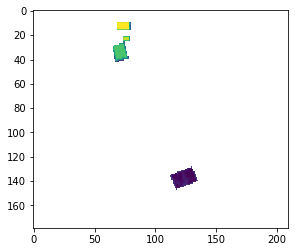

In [7]:
import rasterio.mask
import rasterio as rio
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# path = "data/rooftop_preds_slope_aspect.tif"
# with rio.open(path) as src:
#     out_image = src.read(1)

# plt.imshow(out_image)
plt.imshow(output_raster[0])

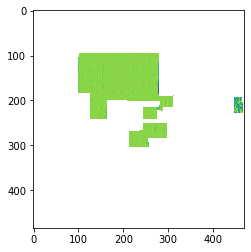

In [5]:
import rasterio.mask
import rasterio as rio
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# path = "data/rooftop_preds_slope_aspect.tif"
# with rio.open(path) as src:
#     out_image = src.read(1)

# plt.imshow(out_image)
plt.imshow(output_raster[0])

### Temp code

In [36]:
start = '2023-01-01'
end = '2023-12-31'

# Create a datetime range for every hour within the year
dt_range = pd.date_range(start, end, freq='D')

# Latitude and longitude for a specific location (e.g., New York City)
latitude, longitude = 12.971599, 77.594566

# Create the DataFrame
df = pd.DataFrame(dt_range, columns=['datetime'])
df['lat'] = latitude
df['lon'] = longitude

In [39]:
import pandas as pd
import requests
from datetime import datetime

def get_cloud_cover(lat, lon, dt):
    api_key = 'YOUR_OPENWEATHERMAP_KEY'
    url = f'https://api.openweathermap.org/data/2.5/weather?lat={lat}&lon={lon}&dt={int(dt.timestamp())}&appid={api_key}'
    response = requests.get(url)
    
    if response.status_code == 200:
        data = response.json()
        print(data)
        cloud_cover = data['clouds']['all']
        return cloud_cover
    else:
        print(f"Error fetching data: {response.status_code}")
        return None

df = df.head(30)

# Assuming you have a pandas DataFrame named 'df' with columns 'latitude', 'longitude', and 'datetime'
df['cloud_cover'] = df.apply(lambda row: get_cloud_cover(row['lat'], row['lon'], row['datetime']), axis=1)

print(df.head())

{'coord': {'lon': 77.5946, 'lat': 12.9716}, 'weather': [{'id': 802, 'main': 'Clouds', 'description': 'scattered clouds', 'icon': '03d'}], 'base': 'stations', 'main': {'temp': 300.64, 'feels_like': 302.97, 'temp_min': 298, 'temp_max': 301.74, 'pressure': 1011, 'humidity': 71}, 'visibility': 6000, 'wind': {'speed': 1.03, 'deg': 0}, 'clouds': {'all': 40}, 'dt': 1716264942, 'sys': {'type': 2, 'id': 2017753, 'country': 'IN', 'sunrise': 1716250995, 'sunset': 1716296970}, 'timezone': 19800, 'id': 1277333, 'name': 'Bengaluru', 'cod': 200}
{'coord': {'lon': 77.5946, 'lat': 12.9716}, 'weather': [{'id': 802, 'main': 'Clouds', 'description': 'scattered clouds', 'icon': '03d'}], 'base': 'stations', 'main': {'temp': 300.64, 'feels_like': 302.97, 'temp_min': 298, 'temp_max': 301.74, 'pressure': 1011, 'humidity': 71}, 'visibility': 6000, 'wind': {'speed': 1.03, 'deg': 0}, 'clouds': {'all': 40}, 'dt': 1716264942, 'sys': {'type': 2, 'id': 2017753, 'country': 'IN', 'sunrise': 1716250995, 'sunset': 171629

In [40]:
tzwhere = tzwhere.tzwhere()

# variables needed 
buildings = gpd.read_file('data/solar_rooftop.geojson') # footprint geometry

polygon = buildings.geometry.iloc[0]
latitude, longitude = polygon.centroid.y, polygon.centroid.x
timezone_str = tzwhere.tzNameAt(latitude, longitude)

c:\ProgramData\Anaconda3\envs\geo\lib\site-packages\tzwhere\tzwhere.py:62: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  self.timezoneNamesToPolygons[tzname] = WRAP(polys)


In [65]:
latitude, longitude

(14.698221089739905, 120.28076077133083)

In [41]:
timezone_str

'Asia/Manila'

In [67]:
import openmeteo_requests

def get_cloud_cover(lat, lon, timezone, year=2023):
	openmeteo = openmeteo_requests.Client()

	url = "https://archive-api.open-meteo.com/v1/archive"
	
	params = {
		"latitude": lat,
		"longitude": lon,
		"hourly": "cloud_cover",
		"timezone": timezone,
		"start_date": f"{year}-01-01",
		"end_date": f"{year}-12-31"
	}
	responses = openmeteo.weather_api(url, params=params)

	# Process first location. Add a for-loop for multiple locations or weather models
	response = responses[0]
	print(f"Coordinates {response.Latitude()}°N {response.Longitude()}°E")
	print(f"Elevation {response.Elevation()} m asl")
	print(f"Timezone {response.Timezone()} {response.TimezoneAbbreviation()}")
	print(f"Timezone difference to GMT+0 {response.UtcOffsetSeconds()} s")

	# Process hourly data. The order of variables needs to be the same as requested.
	hourly = response.Hourly()
	hourly_cloud_cover = hourly.Variables(0).ValuesAsNumpy()

	return hourly_cloud_cover

Coordinates 14.727592468261719°N 120.30697631835938°E
Elevation 17.0 m asl
Timezone b'Asia/Manila' b'PST'
Timezone difference to GMT+0 28800 s


,date,cloud_cover
0,2022-12-31 16:00:00+00:00,18.900002
1,2022-12-31 17:00:00+00:00,32.400002
2,2022-12-31 18:00:00+00:00,30.900002
3,2022-12-31 19:00:00+00:00,38.099998
4,2022-12-31 20:00:00+00:00,49.500000
...,...,...
8755,2023-12-31 11:00:00+00:00,30.000002
8756,2023-12-31 12:00:00+00:00,35.700001
8757,2023-12-31 13:00:00+00:00,25.800001
8758,2023-12-31 14:00:00+00:00,33.299999


<AxesSubplot:>

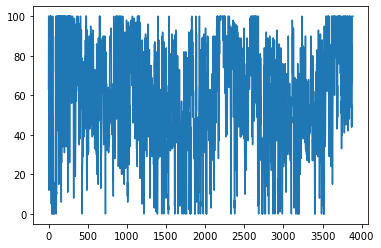

In [64]:
hourly_dataframe['cloud_cover'].plot()

In [62]:
hourly_dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3912 entries, 0 to 3911
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   date         3912 non-null   datetime64[ns, UTC]
 1   cloud_cover  3905 non-null   float32            
dtypes: datetime64[ns, UTC](1), float32(1)
memory usage: 46.0 KB


In [68]:
year = 2023
times = pd.date_range(f'{year}-01-01 00:00:00', f'{year}-12-31 23:59:59', freq='1h', tz= site_location.tz)


In [69]:
times

DatetimeIndex(['2023-01-01 00:00:00+08:00', '2023-01-01 01:00:00+08:00',
               '2023-01-01 02:00:00+08:00', '2023-01-01 03:00:00+08:00',
               '2023-01-01 04:00:00+08:00', '2023-01-01 05:00:00+08:00',
               '2023-01-01 06:00:00+08:00', '2023-01-01 07:00:00+08:00',
               '2023-01-01 08:00:00+08:00', '2023-01-01 09:00:00+08:00',
               ...
               '2023-12-31 14:00:00+08:00', '2023-12-31 15:00:00+08:00',
               '2023-12-31 16:00:00+08:00', '2023-12-31 17:00:00+08:00',
               '2023-12-31 18:00:00+08:00', '2023-12-31 19:00:00+08:00',
               '2023-12-31 20:00:00+08:00', '2023-12-31 21:00:00+08:00',
               '2023-12-31 22:00:00+08:00', '2023-12-31 23:00:00+08:00'],
              dtype='datetime64[ns, Asia/Manila]', length=8760, freq='H')

In [19]:
data = out_image
data.size - np.isnan(data).sum()

612

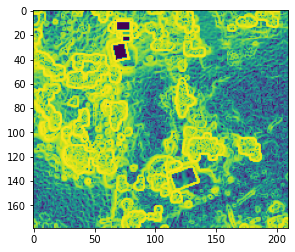

In [33]:
from scipy.ndimage import sobel

# Calculate the gradient in x and y directions
dx = sobel(out_image, axis=1)  # Sobel filter to calculate gradient along x-axis
dy = sobel(out_image, axis=0)  # Sobel filter to calculate gradient along y-axis
slope = np.arctan(np.sqrt(dx**2 + dy**2))

slope_degrees = np.degrees(slope)

plt.imshow(slope_degrees)

2459.049


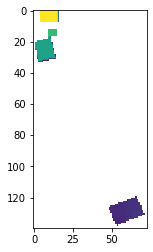

In [23]:
print(np.nanmax(output_raster))
plt.imshow(output_raster[0])

In [21]:

np.nanmean(out_image[0])

27.726652

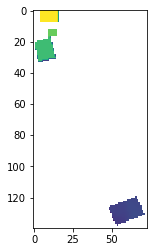

In [19]:
plt.imshow(out_image[0])

In [33]:
dni_extra = pvlib.irradiance.get_extra_radiation(times)
dni_extra.head(24)

2024-01-01 00:00:00+08:00    1413.981805
2024-01-01 01:00:00+08:00    1413.981805
2024-01-01 02:00:00+08:00    1413.981805
2024-01-01 03:00:00+08:00    1413.981805
2024-01-01 04:00:00+08:00    1413.981805
2024-01-01 05:00:00+08:00    1413.981805
2024-01-01 06:00:00+08:00    1413.981805
2024-01-01 07:00:00+08:00    1413.981805
2024-01-01 08:00:00+08:00    1413.981805
2024-01-01 09:00:00+08:00    1413.981805
2024-01-01 10:00:00+08:00    1413.981805
2024-01-01 11:00:00+08:00    1413.981805
2024-01-01 12:00:00+08:00    1413.981805
2024-01-01 13:00:00+08:00    1413.981805
2024-01-01 14:00:00+08:00    1413.981805
2024-01-01 15:00:00+08:00    1413.981805
2024-01-01 16:00:00+08:00    1413.981805
2024-01-01 17:00:00+08:00    1413.981805
2024-01-01 18:00:00+08:00    1413.981805
2024-01-01 19:00:00+08:00    1413.981805
2024-01-01 20:00:00+08:00    1413.981805
2024-01-01 21:00:00+08:00    1413.981805
2024-01-01 22:00:00+08:00    1413.981805
2024-01-01 23:00:00+08:00    1413.981805
Freq: H, dtype: 

In [ ]:
# Clear-sky solar irradiance
airmass = pvlib.atmosphere.get_relative_airmass(solpos['apparent_zenith'])
pressure = pvlib.atmosphere.alt2pres()
airmass = pvlib.atmosphere.get_absolute_airmass(airmass, pressure)
linke_turbidity = pvlib.clearsky.lookup_linke_turbidity(times, latitude, longitude)
clrsky = pvlib.clearsky.ineichen(solpos['apparent_zenith'], airmass, linke_turbidity, altitude=building_elevation, dni_extra=dni_extra)

# Total irradiance on the horizontal surface
irradiance = pvlib.irradiance.get_total_irradiance(
    surface_tilt,
    surface_azimuth,
    solpos['apparent_zenith'],
    solpos['azimuth'],
    clrsky['dni'],
    clrsky['ghi'],
    clrsky['dhi']
)

annual_irradiance = irradiance['poa_global'].sum()
print("Annual Solar Irradiance without Shading (kWh/m^2):", annual_irradiance / 1000)